# 02 - Exploratory Data Analysis (RAVDESS speech)


In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("../images", exist_ok=True)
os.makedirs("../data", exist_ok=True)

EMOTIONS = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

import librosa, librosa.display
from scipy.stats import kruskal

In [2]:
df = pd.read_csv("../data/clean_metadata.csv")
print(df.shape)
df[["filename", "emotion", "intensity", "actor", "gender", "dur_raw", "dur_trim", "rms", "peak", "silence_ratio"]].head()

(1439, 21)


,filename,emotion,intensity,actor,gender,dur_raw,dur_trim,rms,peak,silence_ratio
0,03-01-01-01-01-01-01.wav,neutral,normal,1,male,3.303311,1.300317,0.003999,0.041009,0.606359
1,03-01-01-01-01-02-01.wav,neutral,normal,1,male,3.336689,1.300317,0.004280,0.047185,0.610297
2,03-01-01-01-02-01-01.wav,neutral,normal,1,male,3.269932,1.277098,0.005076,0.058744,0.609442
3,03-01-01-01-02-02-01.wav,neutral,normal,1,male,3.169841,1.230658,0.004875,0.061837,0.611760
4,03-01-02-01-01-01-01.wav,calm,normal,1,male,3.536871,1.555737,0.002954,0.026036,0.560137


# 2. Class balance

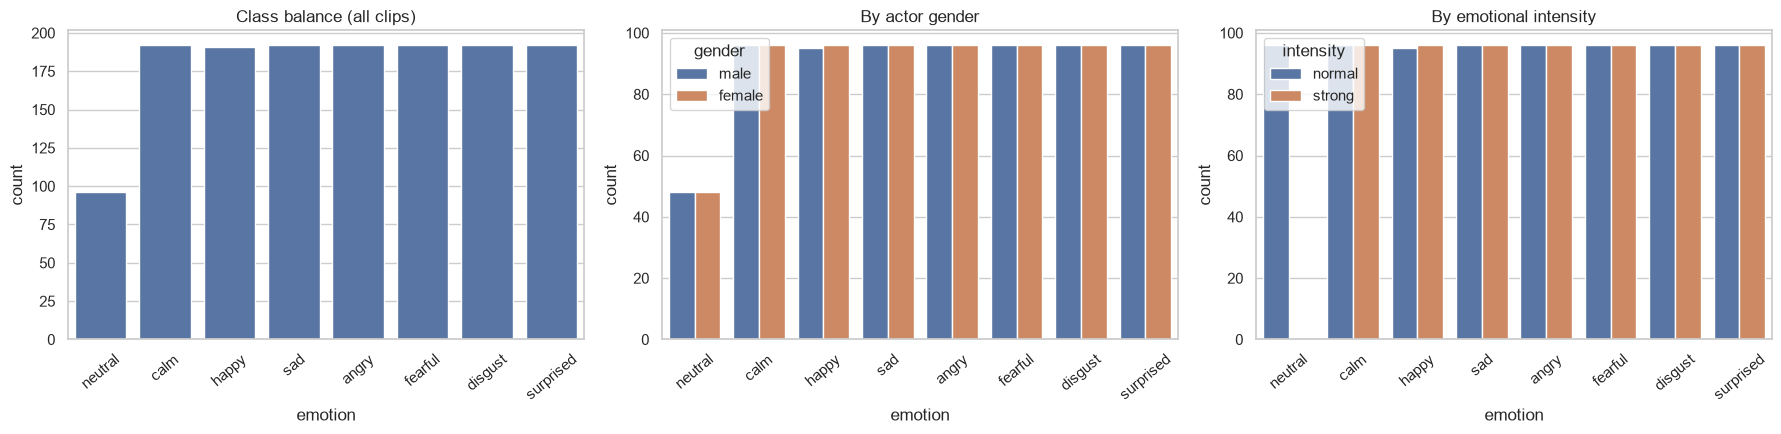

emotion
neutral       96
calm         192
happy        191
sad          192
angry        192
fearful      192
disgust      192
surprised    192
Name: count, dtype: int64

intensity  normal  strong
emotion                  
neutral        96       0
calm           96      96
happy          95      96
sad            96      96
angry          96      96
fearful        96      96
disgust        96      96
surprised      96      96


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=df, x="emotion", order=EMOTIONS, ax=axes[0], color="#4C72B0")
axes[0].set_title("Class balance (all clips)")
sns.countplot(data=df, x="emotion", hue="gender", order=EMOTIONS, ax=axes[1])
axes[1].set_title("By actor gender")
sns.countplot(data=df, x="emotion", hue="intensity", order=EMOTIONS, ax=axes[2])
axes[2].set_title("By emotional intensity")
for a in axes:
    a.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.savefig("../images/eda_class_balance.png", dpi=140)
plt.show()

print(df["emotion"].value_counts().reindex(EMOTIONS))
print()
print(pd.crosstab(df["emotion"], df["intensity"]).reindex(EMOTIONS))

every emotion has the same number of clips except **neutral, which has about half** (it only exists at "normal" intensity, there is no "strong" neutral in RAVDESS). Gender is balanced within every emotion. Modeling consequence: use `class_weight="balanced"` (classical ML) or a weighted loss (CNN), and report **macro** F1, not only accuracy.

# 3. Speakers (actors)


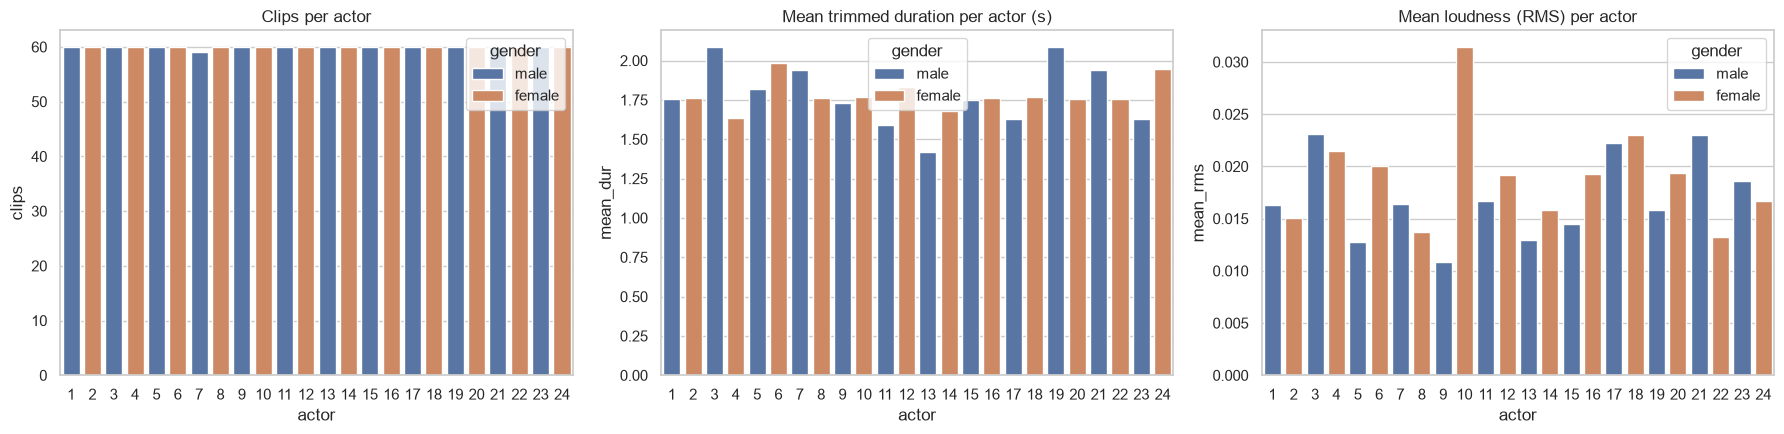

,actor,clips,mean_dur,mean_rms
count,24.000,24.000,24.000,24.000
mean,12.500,59.958,1.783,0.018
std,7.071,0.204,0.157,0.005
min,1.000,59.000,1.417,0.011
25%,6.750,60.000,1.718,0.015
50%,12.500,60.000,1.760,0.017
75%,18.250,60.000,1.859,0.020
max,24.000,60.000,2.087,0.031


In [4]:
actor_stats = df.groupby(["actor", "gender"]).agg(clips=("filename", "count"),
                                                 mean_dur=("dur_trim", "mean"),
                                                 mean_rms=("rms", "mean")).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.barplot(data=actor_stats, x="actor", y="clips", hue="gender", ax=axes[0], dodge=False)
axes[0].set_title("Clips per actor")
sns.barplot(data=actor_stats, x="actor", y="mean_dur", hue="gender", ax=axes[1], dodge=False)
axes[1].set_title("Mean trimmed duration per actor (s)")
sns.barplot(data=actor_stats, x="actor", y="mean_rms", hue="gender", ax=axes[2], dodge=False)
axes[2].set_title("Mean loudness (RMS) per actor")
plt.tight_layout()
plt.savefig("../images/eda_actor_variation.png", dpi=140)
plt.show()
actor_stats.describe().round(3)

every actor contributes the same number of clips, but actors differ clearly in speaking pace and loudness. This is the reason for splitting **by actor** (never randomly by clip): a random split would leak each speaker's voice into the test set and inflate accuracy.

# 4. Clip duration


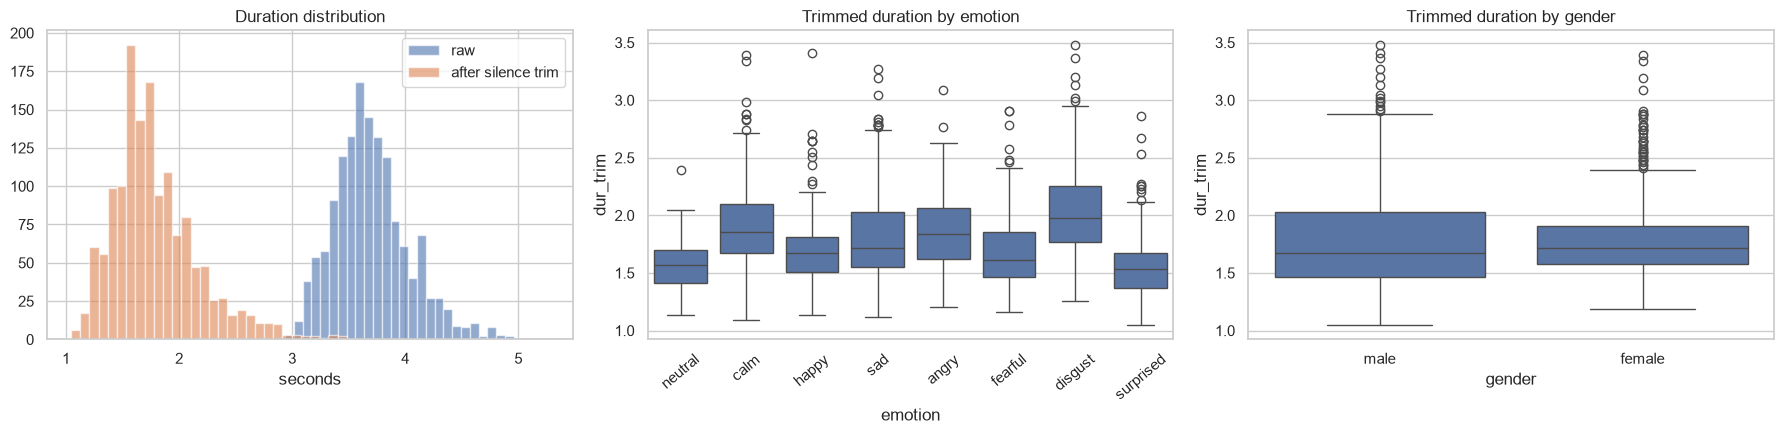

       dur_raw  dur_trim
count  1439.00   1439.00
mean      3.70      1.78
std       0.34      0.38
min       2.94      1.04
25%       3.47      1.53
50%       3.67      1.70
75%       3.87      1.97
max       5.27      3.48

Clips longer than 4 s after trimming: 0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(df["dur_raw"], bins=30, alpha=.6, label="raw")
axes[0].hist(df["dur_trim"], bins=30, alpha=.6, label="after silence trim")
axes[0].set_xlabel("seconds"); axes[0].set_title("Duration distribution"); axes[0].legend()
sns.boxplot(data=df, x="emotion", y="dur_trim", order=EMOTIONS, ax=axes[1])
axes[1].set_title("Trimmed duration by emotion"); axes[1].tick_params(axis="x", rotation=40)
sns.boxplot(data=df, x="gender", y="dur_trim", ax=axes[2])
axes[2].set_title("Trimmed duration by gender")
plt.tight_layout()
plt.savefig("../images/eda_durations.png", dpi=140)
plt.show()
print(df[["dur_raw", "dur_trim"]].describe().round(2))
print("\nClips longer than 4 s after trimming:", int((df["dur_trim"] > 4.0).sum()))

raw clips are about 3-5 s with leading and trailing silence; trimming makes them shorter and tighter. Duration also differs by emotion, so it is itself a useful cue (the extended feature set already includes it). Almost all trimmed clips fit in **4 seconds**, which is why both pipelines use a 4 s window (cap longer clips, pad shorter ones).

# Loudness, peak and silence by emotion

energy is one of the most basic acoustic cues of emotion. Note that the pipeline later peak-normalizes each clip, so absolute loudness differences are removed there, and this plot shows what we deliberately remove.

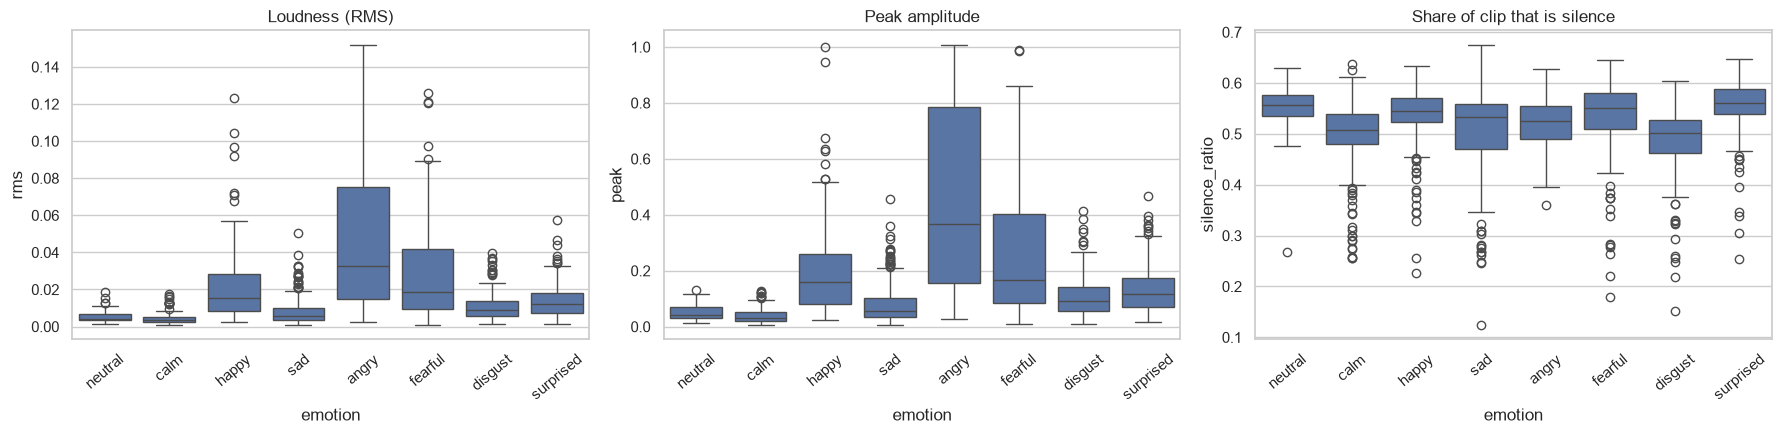

,dur_trim,rms,peak,silence_ratio
emotion,,,,
neutral,1.563,0.005,0.054,0.555
calm,1.930,0.004,0.039,0.495
happy,1.696,0.021,0.200,0.536
sad,1.844,0.009,0.084,0.504
angry,1.855,0.046,0.461,0.524
fearful,1.677,0.028,0.266,0.532
disgust,2.034,0.011,0.110,0.487
surprised,1.552,0.014,0.133,0.557


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c, t in zip(axes, ["rms", "peak", "silence_ratio"],
                    ["Loudness (RMS)", "Peak amplitude", "Share of clip that is silence"]):
    sns.boxplot(data=df, x="emotion", y=c, order=EMOTIONS, ax=ax)
    ax.set_title(t); ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.savefig("../images/eda_loudness_silence.png", dpi=140)
plt.show()

summary = df.groupby("emotion")[["dur_trim", "rms", "peak", "silence_ratio"]].mean().reindex(EMOTIONS).round(3)
summary

In [7]:
# Do the emotions really differ on these statistics? Kruskal-Wallis (non-parametric, no normality assumed)
for c in ["rms", "peak", "dur_trim", "silence_ratio"]:
    groups = [df.loc[df["emotion"] == e, c] for e in EMOTIONS]
    stat, p = kruskal(*groups)
    print(f"{c:15s} H = {stat:8.1f}   p = {p:.2e}")

rms             H =    627.3   p = 3.13e-131
peak            H =    632.5   p = 2.49e-132
dur_trim        H =    293.1   p = 1.79e-59
silence_ratio   H =    253.5   p = 5.04e-51


the table of means and the Kruskal-Wallis test show whether emotions differ significantly on each statistic (a very small p-value means they do). Emotions such as angry and fearful sit at the loud/fast end, and calm and sad at the quiet/slow end. Because these are real emotional differences, the outlier clips flagged in notebook 01 are kept.

# 6. Effect of emotional intensity

each emotion (except neutral) is recorded at "normal" and "strong" intensity. If strong clips are very different, the model sees two sub-populations per emotion.

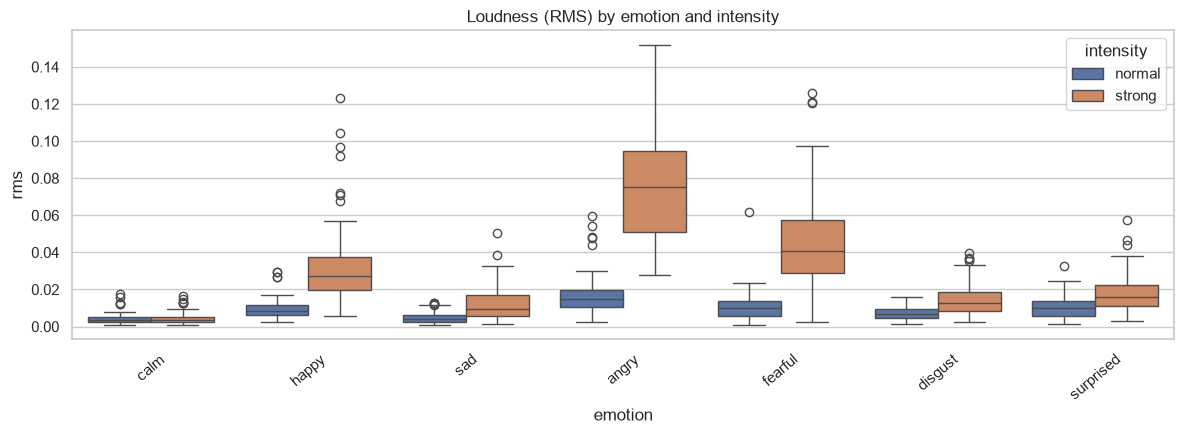

In [8]:
plt.figure(figsize=(12, 4.5))
sns.boxplot(data=df[df["emotion"] != "neutral"], x="emotion", y="rms",
            hue="intensity", order=[e for e in EMOTIONS if e != "neutral"])
plt.title("Loudness (RMS) by emotion and intensity")
plt.xticks(rotation=40)
plt.tight_layout()
plt.savefig("../images/eda_intensity_effect.png", dpi=140)
plt.show()

**What it shows:** strong-intensity clips are generally louder than normal-intensity clips of the same emotion, so intensity adds within-class variation. Strong and normal versions are also the easiest to tell apart, which means the harder confusions are expected *between* emotions at normal intensity.

# 7. Statements and repetitions

In [9]:
print(pd.crosstab(df["emotion"], df["statement"]).reindex(EMOTIONS))
print()
print(df["repetition"].value_counts())

statement  Dogs are sitting by the door  Kids are talking by the door
emotion                                                              
neutral                              48                            48
calm                                 96                            96
happy                                95                            96
sad                                  96                            96
angry                                96                            96
fearful                              96                            96
disgust                              96                            96
surprised                            96                            96

repetition
1    720
2    719
Name: count, dtype: int64


# 7b. Correlation heatmap of the audio statistics


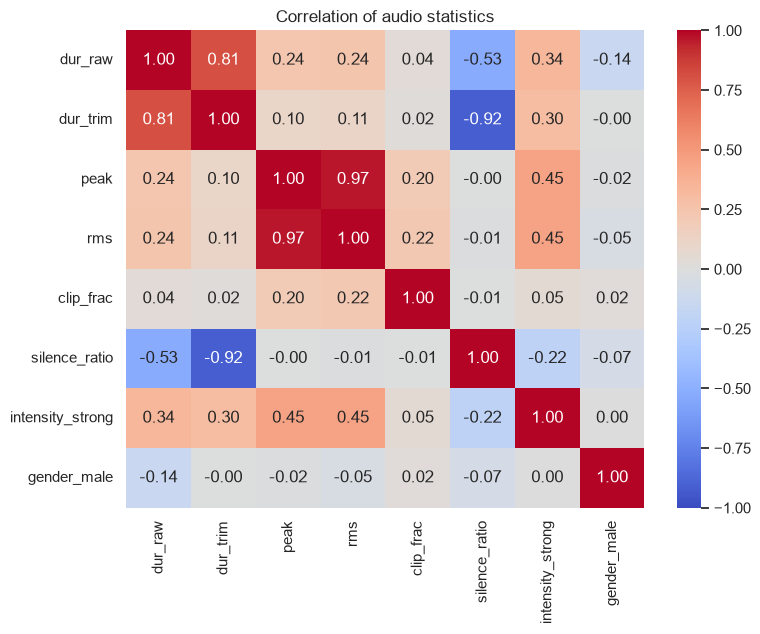

In [10]:
corr_df = df[["dur_raw", "dur_trim", "peak", "rms", "clip_frac", "silence_ratio"]].copy()
corr_df["intensity_strong"] = (df["intensity"] == "strong").astype(int)
corr_df["gender_male"] = (df["gender"] == "male").astype(int)
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of audio statistics")
plt.tight_layout()
plt.savefig("../images/eda_correlation_heatmap.png", dpi=140)
plt.show()

# 8. What the audio looks like: one example per emotion


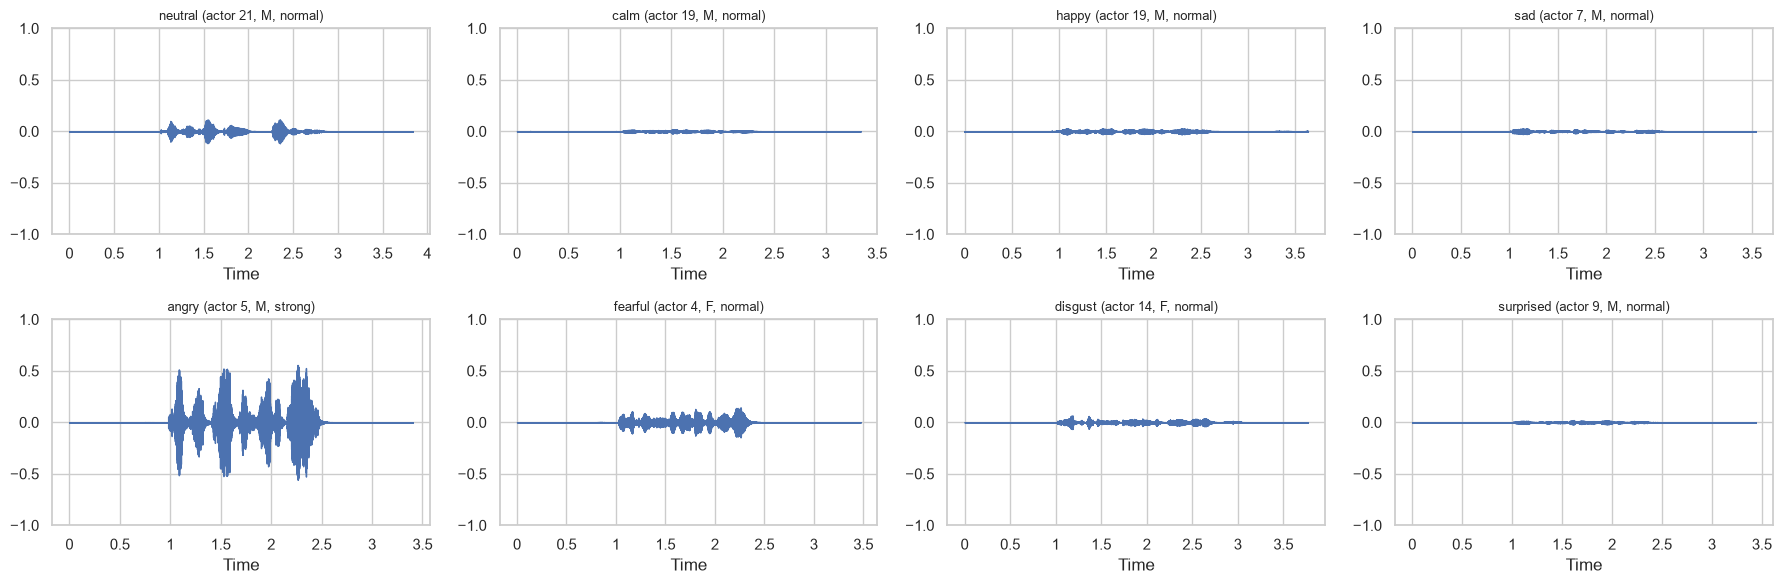

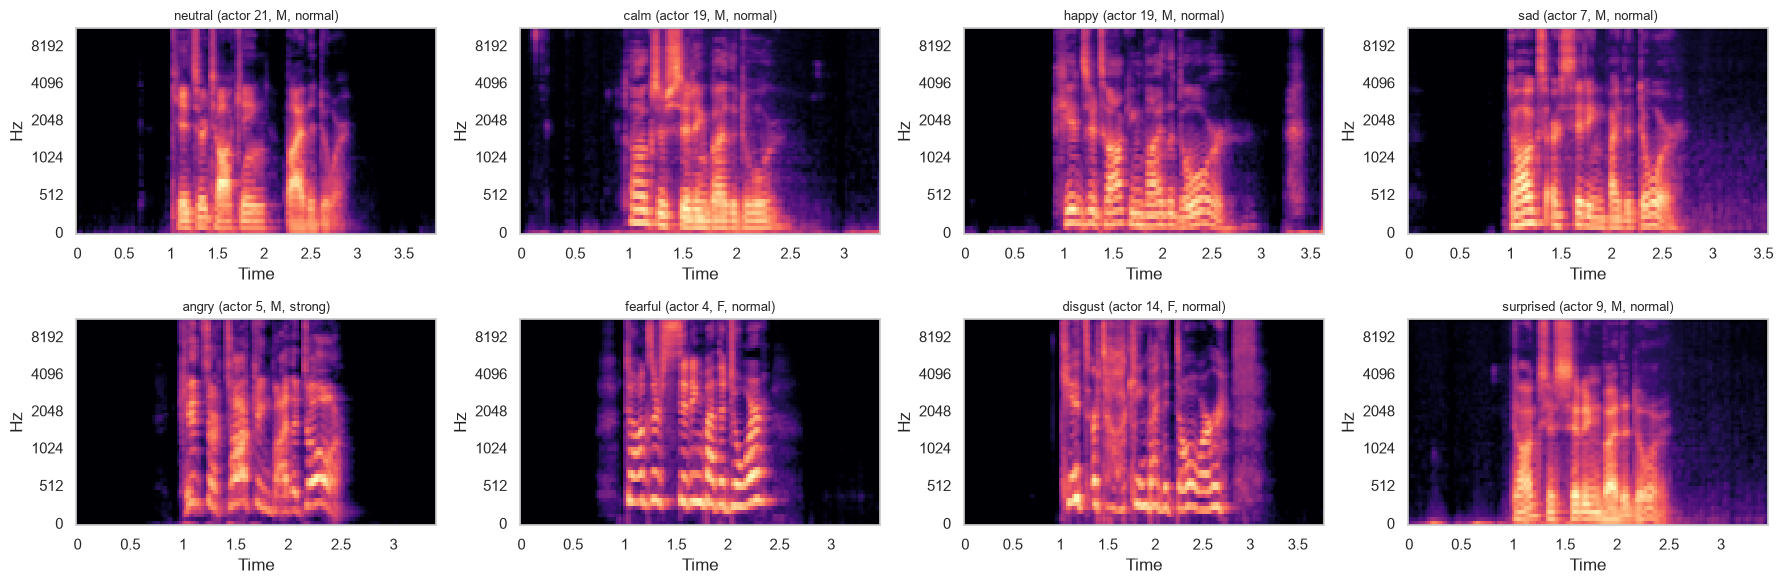

In [11]:
SR = 22050
rng = np.random.RandomState(42)
samples = {e: df[df["emotion"] == e].sample(1, random_state=rng).iloc[0] for e in EMOTIONS}

for kind in ("waveform", "melspec"):
    fig, axes = plt.subplots(2, 4, figsize=(18, 6))
    for ax, (emo, row) in zip(axes.ravel(), samples.items()):
        y, sr = librosa.load(row["path"], sr=SR)
        if kind == "waveform":
            librosa.display.waveshow(y, sr=sr, ax=ax, color="#4C72B0")
            ax.set_ylim(-1, 1)
        else:
            S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64), ref=np.max)
            librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="mel", ax=ax)
        ax.set_title(f"{emo} (actor {row['actor']}, {row['gender'][0].upper()}, {row['intensity']})", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"../images/eda_{kind}_per_emotion.png", dpi=140)
    plt.show()

## 9. Key findings from the EDA

1. **Complete, balanced data:** 24 actors x 60 clips, balanced by gender. The only imbalance is **neutral (about half as many clips)**.
2. **Speaker differences are real:** actors differ in pace and loudness, so the split must be **speaker-independent**.
3. **Fixed 4 s window is enough:** nearly all clips are under 4 s after trimming, so cap at 4 s (CNN: pad shorter clips).
4. **Emotions differ in loudness, speed and silence share** (Kruskal-Wallis test), but peak-normalizing removes absolute loudness, so models must rely on spectral and timing cues.
5. **Intensity adds within-class variation** (strong clips are louder), and neutral has no strong version.
6. **Words carry no information:** two sentences only, so the signal is purely in *how* they are spoken.
7. **Modeling plan:** class weights or weighted loss, macro-F1 as the main metric, augmentation because the dataset is small (about 1,440 clips).